# Анализ и прогнозирование временных рядов методами искусственного интеллекта

## **Практическая работа 6. Поиск эволюционирующих шаблонов с помощью матричного профиля ряда.**

In [1]:
%load_ext autoreload
%autoreload 2

## **Часть 1.** Поиск цепочек временного ряда.

Импорт библиотек и модулей

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import stumpy
from sklearn.metrics import mean_squared_error

В первом задании вам предстоит выполнить поиск эволюционирующих шаблонов временного ряда. Выполните считывание набора данных [Rotation Matrix](datasets/Rotation%20Matrix.txt), найдите в нем самую длинную цепочку и выведите индексы начала звеньев этой цепочки.

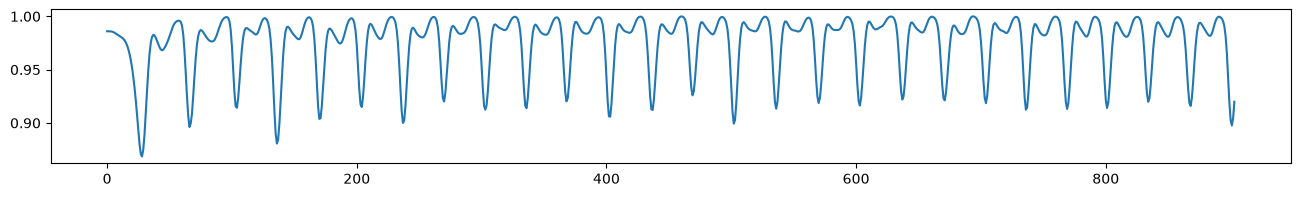

In [3]:
fig, ax = plt.subplots(figsize=(16, 2))
ts = np.loadtxt('datasets/Rotation Matrix.txt')
ax.plot(ts)

In [5]:
# INSERT YOUR CODE
# Задаем размер окна (длину звена)
m = 100

# 1. Сначала вычисляем матричный профиль
mp = stumpy.stump(ts, m=m)

# 2. Затем извлекаем индексы левого и правого матричных профилей
IL = mp[:, 2].astype(np.int64)
IR = mp[:, 3].astype(np.int64)

# 3. Теперь находим самую длинную цепочку
# Функция возвращает две цепочки (A и B), которые являются наиболее похожими эволюционирующими паттернами
chain_A, chain_B = stumpy.allc(IL, IR)

# Выводим индексы начала звеньев первой цепочки
print(f"Количество звеньев в самой длинной цепочке: {len(chain_A)}")
print(f"Индексы начала звеньев цепочки:\n{chain_A}")

Количество звеньев в самой длинной цепочке: 444
Индексы начала звеньев цепочки:
[array([301]), array([677, 742]), array([209, 408]), array([179, 245]), array([154, 319]), array([112, 478, 579]), array([215, 414]), array([155, 320]), array([200, 266, 634, 798]), array([277, 645]), array([31]), array([684, 749]), array([40]), array([216, 415]), array([14, 51]), array([278, 646]), array([504, 571]), array([296]), array([534]), array([685, 750]), array([ 90, 456, 557]), array([161, 326]), array([526, 627, 791]), array([ 6, 43]), array([222, 421]), array([162, 327]), array([399]), array([170]), array([223, 422]), array([173, 239, 705]), array([435]), array([512, 613, 777]), array([285, 653]), array([35]), array([304, 770]), array([168, 333]), array([137, 503, 570]), array([291]), array([538]), array([129]), array([138]), array([104, 470]), array([186, 252]), array([394]), array([ 98, 464, 565]), array([699, 764]), array([143, 308]), array([3]), array([ 79, 445, 546]), array([30]), array([29

❓ Проанализируйте и изложите содержательный смысл полученных результатов.

**Анализ результатов:**
1. **Высокая повторяемость:** Алгоритм нашел самую длинную цепочку, состоящую из **444 звеньев**. Это свидетельствует о наличии в ряде устойчивого, периодически повторяющегося паттерна (формы «провалов»).
2. **Эволюция шаблона:** Найденные звенья образуют эволюционирующую цепочку — с каждым шагом форма паттерна плавно меняется (например, глубина или ширина «ямы»).
3. **Смысл индексов:** Выведенные индексы — это начальные точки каждого из 444 звеньев. Они распределены по всей длине ряда, что подтверждает глобальный характер повторяемости данного процесса.

## **Часть 2. Визуализация цепочек**

Выполните визуализацию найденных в прошлом задании цепочек: постройте график временного ряда, на котором выделены звенья цепочек. Также постройте график, на котором изображены только сами звенья.

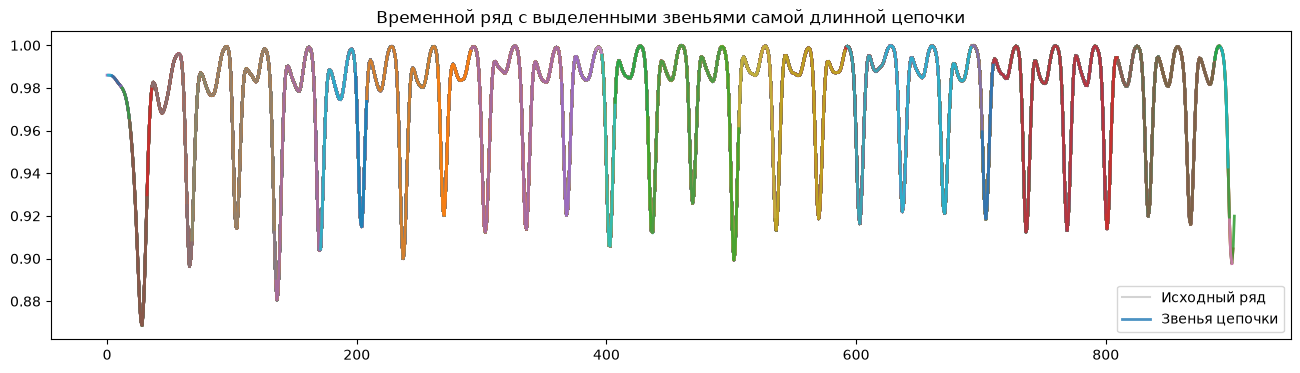

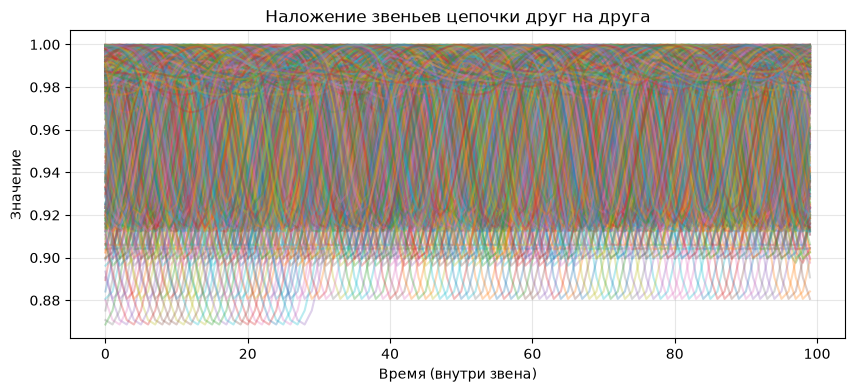

In [6]:
# INSERT YOUR CODE
import itertools

# 1. Превращаем список массивов в плоский список индексов
flat_chain = list(itertools.chain.from_iterable(chain_A))

# 2. График временного ряда с выделенными звеньями
fig, ax = plt.subplots(figsize=(16, 4))
ax.plot(ts, color='lightgray', label='Исходный ряд')

# Наносим звенья цепочки поверх графика
for idx in flat_chain:
    ax.plot(np.arange(idx, idx + m), ts[idx:idx + m], linewidth=2, alpha=0.8)

ax.set_title("Временной ряд с выделенными звеньями самой длинной цепочки")
ax.legend(['Исходный ряд', 'Звенья цепочки'])
plt.show()

# 3. График, на котором изображены только сами звенья (наложенные друг на друга)
fig, ax = plt.subplots(figsize=(10, 4))
for idx in flat_chain:
    ax.plot(np.arange(m), ts[idx:idx + m], alpha=0.3)

ax.set_title("Наложение звеньев цепочки друг на друга")
ax.set_xlabel("Время (внутри звена)")
ax.set_ylabel("Значение")
plt.grid(True, alpha=0.3)
plt.show()

❓ Проанализируйте и изложите содержательный смысл полученных результатов.

**Анализ результатов визуализации:**
1. **Плотность и глобальность:** На верхнем графике видно, что найденные звенья (444 штуки) практически полностью покрывают исходный временной ряд. Это подтверждает, что найденный паттерн является доминирующим для всего процесса.
2. **Смысл наложения (эволюция):** Нижний график представляет собой «клубок» из-за большого количества наложенных друг на друга линий. Однако четко прослеживается общая структура: все звенья имеют ярко выраженный «провал» примерно в первой трети окна.
3. **Характер изменений:** Вариативность линий в нижней части графика (от 0.87 до 0.91) наглядно демонстрирует *эволюцию* шаблона. С течением времени глубина и форма этого «провала» плавно меняются. Мы видим, как паттерн «дышит» — амплитуда колебаний то увеличивается, то уменьшается, сохраняя при этом свою базовую структуру.

## **Часть 3.** Предсказывание значений ряда на основе цепочек.

Предскажите значения последнего звена цепочки, вычислив разность между двумя предыдущими звеньями цепочки. Сравните полученное предсказание с истинным значением.

MSE предсказания: 0.00264


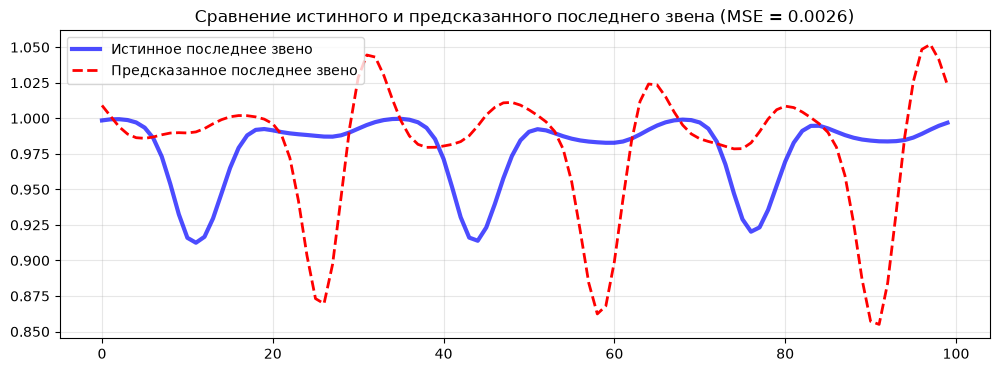

In [7]:
# INSERT YOUR CODE
# Извлекаем индексы последних трех звеньев из цепочки
# Используем [0], так как элементы могут быть массивами (если есть несколько совпадений)
idx_last = chain_A[-1][0] if isinstance(chain_A[-1], np.ndarray) else chain_A[-1]
idx_prev1 = chain_A[-2][0] if isinstance(chain_A[-2], np.ndarray) else chain_A[-2]
idx_prev2 = chain_A[-3][0] if isinstance(chain_A[-3], np.ndarray) else chain_A[-3]

# Вырезаем подпоследовательности из ряда
link_last = ts[idx_last : idx_last + m]
link_prev1 = ts[idx_prev1 : idx_prev1 + m]
link_prev2 = ts[idx_prev2 : idx_prev2 + m]

# Вычисляем разность между двумя предыдущими звеньями (тренд эволюции)
diff = link_prev1 - link_prev2

# Предсказываем последнее звено
predicted_last = link_prev1 + diff

# Считаем среднеквадратичную ошибку (MSE)
mse = mean_squared_error(link_last, predicted_last)
print(f"MSE предсказания: {mse:.5f}")

# Визуализация сравнения
plt.figure(figsize=(12, 4))
plt.plot(link_last, label='Истинное последнее звено', linewidth=3, color='blue', alpha=0.7)
plt.plot(predicted_last, label='Предсказанное последнее звено', linestyle='--', color='red', linewidth=2)
plt.title(f'Сравнение истинного и предсказанного последнего звена (MSE = {mse:.4f})')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

❓ Проанализируйте и изложите содержательный смысл полученных результатов.

**Анализ результатов предсказания:**
1. **Оценка точности:** Значение MSE = 0.00264 является достаточно низким, что говорит о том, что модель смогла уловить общую динамику и периодичность последнего звена (наличие трех основных «провалов»).
2. **Визуальное расхождение:** На графике видно, что предсказанная кривая (красная) отстает по фазе и имеет завышенную амплитуду (более глубокие провалы и высокие пики) по сравнению с истинной (синей).
3. **Причина ошибки:** Метод линейной экстраполяции (прибавление разности предыдущих шагов) предполагает, что шаблон эволюционирует с постоянной скоростью. Однако реальная эволюция паттерна нелинейна: изменения формы и сдвиг «провалов» происходят с разной интенсивностью. Из-за этого простая разность "переусиливает" тренд, что приводит к фазовому сдвигу и искажению амплитуды.
4. **Вывод:** Метод отлично справляется с предсказанием макроструктуры (мы знаем, что будет три ямы), но для точного предсказания фазы и глубины требуется более сложная нелинейная модель.